# 📊 Notebook 01 — EDA, Kiểm Định Rò Rỉ Chính Sách (Leakage Audit) & Tiền Xử Lý

Notebook này thực hiện Khám phá Dữ liệu (EDA), phân tích phân phối nhãn, kiểm định rò rỉ dữ liệu từ các biến chính sách, tạo đặc trưng mới (feature engineering) và chuẩn bị tập dữ liệu cuối cùng cho việc huấn luyện mô hình.

## Section 1: Setup & Imports
Khai báo các thư viện cần thiết, thiết lập môi trường và cấu hình đồ họa.

In [2]:
import sys
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')

# Cấu hình matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 6)

SEED = 42
np.random.seed(SEED)

# Cấu hình đường dẫn
current_dir = Path().resolve()
if (current_dir / 'data').exists():
    BASE_DIR = current_dir
elif (current_dir.parent / 'data').exists():
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir
DATA_DIR = BASE_DIR / 'data'
SRC_DIR = BASE_DIR / 'src'

# Thêm src vào sys.path để import các module tùy chỉnh nếu cần
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

print(f"Thư mục gốc: {BASE_DIR}")


Thư mục gốc: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 4\01. Topic team\Working file


## Section 2: Tải Dữ Liệu, Kiểm Tra Toàn Vẹn & Đánh Giá Chất Lượng Dữ Liệu (Data Quality Audit)

Quy trình kiểm tra toàn diện gồm 7 bước:
1. **Tải dữ liệu & Cấu trúc tổng quan**: Kiểm tra kích thước ma trận dữ liệu (80,000 dòng × 26 cột) và xem trước các dòng đầu/cuối.
2. **Kiểm tra tính toàn vẹn & Trùng lặp (Integrity & Duplicate Audit)**: Đảm bảo không có bản ghi trùng lặp hoàn toàn và mã định danh `id` là duy nhất 100%.
3. **Kiểm toán Cardinality & Vai trò thuộc tính**: Phân loại 26 cột theo vai trò nghiệp vụ (Định danh, Rò rỉ chính sách, Liên tục, Phân loại, Thời gian, Nhị phân).
4. **Kiểm định tính hợp lệ nghiệp vụ & Ngoại lai (Sanity & Anomaly Checks)**: Kiểm tra các ràng buộc tài chính (tuổi 18–100, điểm tín dụng CIC 300–850, số dư không âm, thu nhập > 0, điểm rủi ro trong [0, 1]).
5. **Kiểm tra tính nhất quán logic chéo & Chuỗi thời gian (Cross-feature & Timeline Audit)**: Đối chiếu logic cặp `active_member` vs `digital_behavior` và đảm bảo `last_active_date >= created_date`.
6. **Khảo sát tần suất biến phân loại & Địa bàn**: Phân tích cơ cấu nghề nghiệp, tỉnh thành, phân khúc khách hàng.
7. **Khảo sát hình thái phân phối & Độ lệch (Boxplot & Skewness)**: Xác nhận độ lệch phải nặng của tài sản để bảo đảm tính chuẩn xác của bước Log-transform tiếp theo.


In [3]:
# 2.1 Đọc dữ liệu thô từ file Excel
raw_data_path = DATA_DIR / 'raw' / 'Bank churn data set 80k.xlsx'
df = pd.read_excel(raw_data_path)

print(f"✅ Kích thước tập dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print("=" * 60)
df.info()

# Hiển thị 5 dòng đầu và 5 dòng cuối để kiểm tra format tổng quát
print("\n--- 5 Dòng Đầu Tiên ---")
display(df.head())
print("\n--- 5 Dòng Cuối Cùng ---")
display(df.tail())


✅ Kích thước tập dữ liệu: 80,000 dòng × 26 cột
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      80000 non-null  int64  
 1   full_name               80000 non-null  object 
 2   credit_sco              80000 non-null  int64  
 3   gender                  80000 non-null  object 
 4   age                     80000 non-null  int64  
 5   occupation              80000 non-null  object 
 6   balance                 80000 non-null  int64  
 7   monthly_ir              80000 non-null  int64  
 8   address                 80000 non-null  object 
 9   origin_province         80000 non-null  object 
 10  tenure_ye               80000 non-null  int64  
 11  married                 80000 non-null  int64  
 12  nums_card               80000 non-null  int64  
 13  nums_service            80000 non-null  int6

,id,full_name,credit_sco,gender,age,occupation,balance,monthly_ir,address,origin_province,...,last_transaction_month,created_date,exit,customer_segment,engagement_score,loyalty_level,digital_behavior,risk_score,risk_segment,cluster_group
0,1,Đặng Văn Vũ,725,male,55,Chủ Doanh nghiệp nhỏ,177306004,121000000,Phường An Hội (BT),TP. Hồ Chí Minh,...,91038993,27/02/2025,False,Priority,90,Bronze,mobile,0.0359,Low,4
1,2,Bùi Hữu Phúc,689,male,45,Nội trợ/Sinh viên,1927416,5000000,Phường Bến Thành (Q1),Đồng Nai,...,3255569,29/07/2021,False,Mass,63,Gold,mobile,0.2664,Low,2
2,3,Lê Văn Mai,702,female,44,Chủ Doanh nghiệp nhỏ,304931745,109000000,Phường Hòa Bình (Q11),TP. Hồ Chí Minh,...,0,03/03/2021,False,Priority,36,Silver,offline,0.1343,Low,4
3,4,Dương Trần Nhiên,766,male,44,Chủ Doanh nghiệp nhỏ,50615501,79000000,Phường 7 (Q7),TP. Hồ Chí Minh,...,0,12/02/2022,False,Priority,23,Bronze,offline,0.2185,Low,4
4,5,Dương Thu Linh,677,female,77,Giáo viên/Giảng viên,40532432,25000000,Phường Thắng Lợi (Q10),TP. Hồ Chí Minh,...,0,24/07/2022,False,Emerging,23,Bronze,offline,0.2942,Low,2



--- 5 Dòng Cuối Cùng ---


,id,full_name,credit_sco,gender,age,occupation,balance,monthly_ir,address,origin_province,...,last_transaction_month,created_date,exit,customer_segment,engagement_score,loyalty_level,digital_behavior,risk_score,risk_segment,cluster_group
79995,79996,Dương Anh Chi,682,female,38,Nhân viên văn phòng/Công chức,191593897,18000000,Phường Tân Định (Q1),TP. Hồ Chí Minh,...,0,17/09/2021,False,Affluent,10,Bronze,offline,0.3094,Low,2
79996,79997,Vũ Thu Ánh,710,female,44,Nhân viên văn phòng/Công chức,169955694,29000000,Phường Bến Thành (Q1),Đồng Nai,...,0,29/03/2022,False,Affluent,22,Bronze,offline,0.2209,Low,2
79997,79998,Lê Quang Huy,701,male,62,Kinh doanh/Bán hàng,148475041,31000000,Phường Tân Định (Q1),TP. Hồ Chí Minh,...,213134296,27/03/2022,False,Emerging,68,Gold,mobile,0.1510,Low,3
79998,79999,Hoàng Thanh Châu,619,male,49,Nội trợ/Sinh viên,95040840,12000000,Phường Hòa Bình (Q11),TP. Hồ Chí Minh,...,0,29/03/2021,False,Emerging,14,Bronze,offline,0.3804,Low,2
79999,80000,Bùi Anh Yến,800,female,56,Quản lý/Lãnh đạo,363171524,136000000,Xã Xuân Thới Đông (HM),TP. Hồ Chí Minh,...,0,14/11/2021,False,Priority,34,Bronze,offline,0.1697,Low,4


### 2.2 Kiểm Tra Tính Toàn Vẹn & Trùng Lặp (Duplicate & Identity Audit)
Kiểm tra xem tập dữ liệu có bị xuất hiện các dòng trùng lặp hoàn toàn (full duplicates) hay trùng lặp mã định danh khách hàng (`id`) do lỗi trích xuất ETL hay không.


In [4]:
# Kiểm tra trùng lặp bản ghi hoàn toàn
num_full_dups = int(df.duplicated().sum())
num_id_dups = int(df['id'].duplicated().sum())

print(f"Số lượng bản ghi trùng lặp hoàn toàn (Full duplicate rows) : {num_full_dups}")
print(f"Số lượng mã định danh khách hàng (id) bị trùng lặp        : {num_id_dups}")

if num_full_dups == 0 and num_id_dups == 0:
    print("✅ ĐÁNH GIÁ: Tập dữ liệu đạt chuẩn toàn vẹn 100%, mỗi dòng đại diện cho một khách hàng duy nhất.")
else:
    print("⚠️ CẢNH BÁO: Phát hiện bản ghi trùng lặp, cần xử lý deduplication!")


Số lượng bản ghi trùng lặp hoàn toàn (Full duplicate rows) : 0
Số lượng mã định danh khách hàng (id) bị trùng lặp        : 0
✅ ĐÁNH GIÁ: Tập dữ liệu đạt chuẩn toàn vẹn 100%, mỗi dòng đại diện cho một khách hàng duy nhất.


### 2.3 Bảng Tổng Hợp Cardinality, Missing Values & Phân Loại Vai Trò Thuộc Tính
Bảng tổng kiểm toán cho toàn bộ 26 cột dữ liệu: số lượng giá trị thiếu, tỷ lệ khuyết thiếu, số lượng giá trị duy nhất (Unique Count), tỷ lệ duy nhất (Cardinality Ratio) và định danh vai trò của từng thuộc tính trong kiến trúc mô hình.


In [5]:
# Xây dựng bảng kiểm toán chất lượng thuộc tính (Data Quality & Cardinality Audit Table)
audit_records = []
for col in df.columns:
    col_dtype = str(df[col].dtype)
    missing_count = int(df[col].isnull().sum())
    missing_pct = round(missing_count / len(df) * 100, 2)
    unique_cnt = int(df[col].nunique())
    unique_pct = round(unique_cnt / len(df) * 100, 2)
    
    # Xác định vai trò thuộc tính
    if col in ['id', 'full_name', 'address']:
        role = 'ID / Định danh (Loại bỏ)'
    elif col in ['tenure_ye', 'engagement_score']:
        role = 'Rò rỉ chính sách (Leakage - Loại bỏ)'
    elif col in ['loyalty_level']:
        role = 'Biến mục tiêu (Target)'
    elif col in ['created_date', 'last_active_date']:
        role = 'Timestamp (Chuỗi ngày tháng)'
    elif col in ['active_member', 'exit']:
        role = 'Boolean (Nhị phân)'
    elif unique_cnt <= 10:
        role = 'Phân loại thứ bậc / Nhóm (Categorical)'
    else:
        role = 'Liên tục / Định lượng (Numerical)'
        
    sample_val = str(df[col].dropna().iloc[0]) if len(df[col].dropna()) > 0 else 'N/A'
    if len(sample_val) > 25:
        sample_val = sample_val[:22] + '...'
        
    audit_records.append({
        'Thuộc tính': col,
        'Kiểu dữ liệu': col_dtype,
        'Số giá trị thiếu': missing_count,
        'Tỷ lệ thiếu (%)': f"{missing_pct}%",
        'Số giá trị duy nhất': unique_cnt,
        'Tỷ lệ duy nhất (%)': f"{unique_pct}%",
        'Phân loại vai trò': role,
        'Giá trị mẫu': sample_val
    })

audit_df = pd.DataFrame(audit_records)
display(audit_df)

print(f"Tổng số giá trị khuyết thiếu trên toàn bộ tập dữ liệu: {df.isnull().sum().sum()} giá trị.")
print("✅ Nhận xét: Dữ liệu sạch 100% về mặt missing values, không có cột nào bị thiếu dữ liệu.")


,Thuộc tính,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị duy nhất,Tỷ lệ duy nhất (%),Phân loại vai trò,Giá trị mẫu
0,id,int64,0,0.0%,80000,100.0%,ID / Định danh (Loại bỏ),1
1,full_name,object,0,0.0%,5100,6.38%,ID / Định danh (Loại bỏ),Đặng Văn Vũ
2,credit_sco,int64,0,0.0%,291,0.36%,Liên tục / Định lượng (Numerical),725
3,gender,object,0,0.0%,2,0.0%,Phân loại thứ bậc / Nhóm (Categorical),male
4,age,int64,0,0.0%,71,0.09%,Liên tục / Định lượng (Numerical),55
5,occupation,object,0,0.0%,10,0.01%,Phân loại thứ bậc / Nhóm (Categorical),Chủ Doanh nghiệp nhỏ
6,balance,int64,0,0.0%,79920,99.9%,Liên tục / Định lượng (Numerical),177306004
7,monthly_ir,int64,0,0.0%,209,0.26%,Liên tục / Định lượng (Numerical),121000000
8,address,object,0,0.0%,16,0.02%,ID / Định danh (Loại bỏ),Phường An Hội (BT)
9,origin_province,object,0,0.0%,9,0.01%,Phân loại thứ bậc / Nhóm (Categorical),TP. Hồ Chí Minh


Tổng số giá trị khuyết thiếu trên toàn bộ tập dữ liệu: 0 giá trị.
✅ Nhận xét: Dữ liệu sạch 100% về mặt missing values, không có cột nào bị thiếu dữ liệu.


### 2.4 Kiểm Tra Tính Hợp Lệ Nghiệp Vụ & Phát Hiện Giá Trị Bất Thường (Sanity & Anomaly Checks)
Đối với dữ liệu ngành tài chính - ngân hàng, chúng ta kiểm định các ràng buộc logic thực tế:
- **Độ tuổi (`age`)**: Không được nhỏ hơn 18 (quy định mở tài khoản độc lập) hoặc lớn hơn 100.
- **Điểm tín dụng (`credit_sco`)**: Phải nằm trong dải điểm tiêu chuẩn quốc tế/CIC (300 - 850).
- **Số dư tài khoản (`balance`)**: Phải $\ge 0$ (tiền gửi thanh toán/tiết kiệm không âm).
- **Thu nhập hàng tháng (`monthly_ir`)**: Phải là số dương hợp lệ ($> 0$).
- **Số thẻ (`nums_card`) & Số dịch vụ (`nums_service`)**: Phải nằm trong khoảng hợp lý của khách hàng cá nhân.
- **Điểm rủi ro (`risk_score`)**: Phải nằm trong dải xác suất $[0, 1]$.


In [6]:
# Kiểm tra các ràng buộc nghiệp vụ (Sanity Rules)
sanity_results = []

def check_rule(name, condition, details=""):
    num_violations = int((~condition).sum())
    status = "✅ HỢP LỆ (0 vi phạm)" if num_violations == 0 else f"⚠️ BẤT THƯỜNG ({num_violations:,} vi phạm)"
    sanity_results.append({
        'Kiểm tra nghiệp vụ': name,
        'Trạng thái': status,
        'Số vi phạm': num_violations,
        'Ghi chú / Chi tiết': details
    })

# 1. Tuổi
check_rule("Độ tuổi từ 18 đến 100", (df['age'] >= 18) & (df['age'] <= 100), 
           f"Min = {df['age'].min()} tuổi, Max = {df['age'].max()} tuổi")

# 2. Điểm tín dụng
check_rule("Điểm tín dụng trong khoảng [300, 850]", (df['credit_sco'] >= 300) & (df['credit_sco'] <= 850), 
           f"Min = {df['credit_sco'].min()}, Max = {df['credit_sco'].max()} (Thang chuẩn CIC/FICO)")

# 3. Số dư không âm
check_rule("Số dư tiền gửi (balance) >= 0", df['balance'] >= 0, 
           f"Min = {df['balance'].min():,} VNĐ, Max = {df['balance'].max():,} VNĐ")

# 4. Thu nhập hàng tháng > 0
check_rule("Thu nhập tháng (monthly_ir) > 0", df['monthly_ir'] > 0, 
           f"Min = {df['monthly_ir'].min():,} VNĐ, Max = {df['monthly_ir'].max():,} VNĐ")

# 5. Số thẻ hợp lý (1 - 10 thẻ)
check_rule("Số thẻ tín dụng (nums_card) từ 1 đến 10", (df['nums_card'] >= 1) & (df['nums_card'] <= 10), 
           f"Dải thực tế: {df['nums_card'].min()} đến {df['nums_card'].max()} thẻ")

# 6. Số dịch vụ hợp lý (1 - 20 dịch vụ)
check_rule("Số dịch vụ (nums_service) từ 1 đến 20", (df['nums_service'] >= 1) & (df['nums_service'] <= 20), 
           f"Dải thực tế: {df['nums_service'].min()} đến {df['nums_service'].max()} dịch vụ")

# 7. Điểm rủi ro nằm trong [0, 1]
check_rule("Điểm rủi ro (risk_score) trong [0, 1]", (df['risk_score'] >= 0.0) & (df['risk_score'] <= 1.0), 
           f"Min = {df['risk_score'].min():.4f}, Max = {df['risk_score'].max():.4f}")

# 8. Thâm niên >= 0
check_rule("Thâm niên (tenure_ye) >= 0 năm", df['tenure_ye'] >= 0, 
           f"Min = {df['tenure_ye'].min()} năm, Max = {df['tenure_ye'].max()} năm")

sanity_df = pd.DataFrame(sanity_results)
display(sanity_df)


,Kiểm tra nghiệp vụ,Trạng thái,Số vi phạm,Ghi chú / Chi tiết
0,Độ tuổi từ 18 đến 100,✅ HỢP LỆ (0 vi phạm),0,"Min = 20 tuổi, Max = 90 tuổi"
1,"Điểm tín dụng trong khoảng [300, 850]",✅ HỢP LỆ (0 vi phạm),0,"Min = 495, Max = 800 (Thang chuẩn CIC/FICO)"
2,Số dư tiền gửi (balance) >= 0,✅ HỢP LỆ (0 vi phạm),0,"Min = 408,663 VNĐ, Max = 1,000,000,000 VNĐ"
3,Thu nhập tháng (monthly_ir) > 0,✅ HỢP LỆ (0 vi phạm),0,"Min = 3,000,000 VNĐ, Max = 216,000,000 VNĐ"
4,Số thẻ tín dụng (nums_card) từ 1 đến 10,✅ HỢP LỆ (0 vi phạm),0,Dải thực tế: 1 đến 5 thẻ
5,Số dịch vụ (nums_service) từ 1 đến 20,✅ HỢP LỆ (0 vi phạm),0,Dải thực tế: 1 đến 8 dịch vụ
6,"Điểm rủi ro (risk_score) trong [0, 1]",✅ HỢP LỆ (0 vi phạm),0,"Min = 0.0173, Max = 0.5404"
7,Thâm niên (tenure_ye) >= 0 năm,✅ HỢP LỆ (0 vi phạm),0,"Min = 0 năm, Max = 4 năm"


### 2.5 Kiểm Tra Tính Nhất Quán Logic Chéo & Chuỗi Thời Gian (Cross-Feature & Timeline Audit)
Kiểm tra tính nhất quán giữa các cặp thuộc tính có liên kết logic chặt chẽ:
1. **Quan hệ giữa `active_member` và `digital_behavior`**: Khảo sát sự đồng quy giữa kênh giao dịch (Mobile vs Offline) và trạng thái thành viên tích cực.
2. **Kiểm tra dòng thời gian (`created_date` vs `last_active_date`)**: Chuyển đổi định dạng `datetime` chuẩn `%d/%m/%Y`, kiểm tra không có ngày hoạt động gần nhất nào xảy ra trước ngày tạo tài khoản.
3. **Kiểm toán bất thường cột `last_transaction_month`**: Đánh giá bản chất giá trị của trường này.


In [7]:
# 1. Bảng chéo giữa active_member và digital_behavior
print("--- Ma trận chéo: active_member vs digital_behavior ---")
cross_active_digital = pd.crosstab(df['active_member'], df['digital_behavior'], margins=True)
display(cross_active_digital)

# 2. Kiểm tra chuỗi thời gian created_date và last_active_date
created_dt = pd.to_datetime(df['created_date'], format='%d/%m/%Y', errors='coerce')
last_active_dt = pd.to_datetime(df['last_active_date'], format='%d/%m/%Y', errors='coerce')

null_created = int(created_dt.isnull().sum())
null_active = int(last_active_dt.isnull().sum())
chronological_errors = int((last_active_dt < created_dt).sum())

print(f"\nSố lỗi định dạng ngày ở created_date    : {null_created}")
print(f"Số lỗi định dạng ngày ở last_active_date: {null_active}")
print(f"Số bản ghi có last_active_date < created_date (Mâu thuẫn dòng thời gian): {chronological_errors}")
print(f"Khoảng thời gian mở tài khoản: từ {created_dt.min().strftime('%d/%m/%Y')} đến {created_dt.max().strftime('%d/%m/%Y')}")

# 3. Phân tích cột last_transaction_month
print(f"\nThống kê cột 'last_transaction_month':")
print(f"  Min = {df['last_transaction_month'].min():,}, Max = {df['last_transaction_month'].max():,}, Mean = {df['last_transaction_month'].mean():,.1f}")
print("  -> Nhận định: Giá trị cột này lên tới hàng chục/trăm triệu, đây là số tiền giao dịch tháng gần nhất hoặc mã giao dịch, không phải số tháng (1-12).")


--- Ma trận chéo: active_member vs digital_behavior ---


digital_behavior,mobile,offline,All
active_member,,,
False,0,62824,62824
True,17176,0,17176
All,17176,62824,80000



Số lỗi định dạng ngày ở created_date    : 0
Số lỗi định dạng ngày ở last_active_date: 0
Số bản ghi có last_active_date < created_date (Mâu thuẫn dòng thời gian): 0
Khoảng thời gian mở tài khoản: từ 01/01/2021 đến 01/07/2025

Thống kê cột 'last_transaction_month':
  Min = 0, Max = 600,000,000, Mean = 8,831,755.1
  -> Nhận định: Giá trị cột này lên tới hàng chục/trăm triệu, đây là số tiền giao dịch tháng gần nhất hoặc mã giao dịch, không phải số tháng (1-12).


### 2.6 Khảo Sát Tần Suất Biến Phân Loại & Phân Bổ Địa Bàn (Categorical Frequency Distribution)
Khảo sát cấu trúc phân bố khách hàng theo Nghề nghiệp (`occupation`), Địa bàn (`origin_province`), Phân khúc (`customer_segment`), và Rủi ro (`risk_segment`).


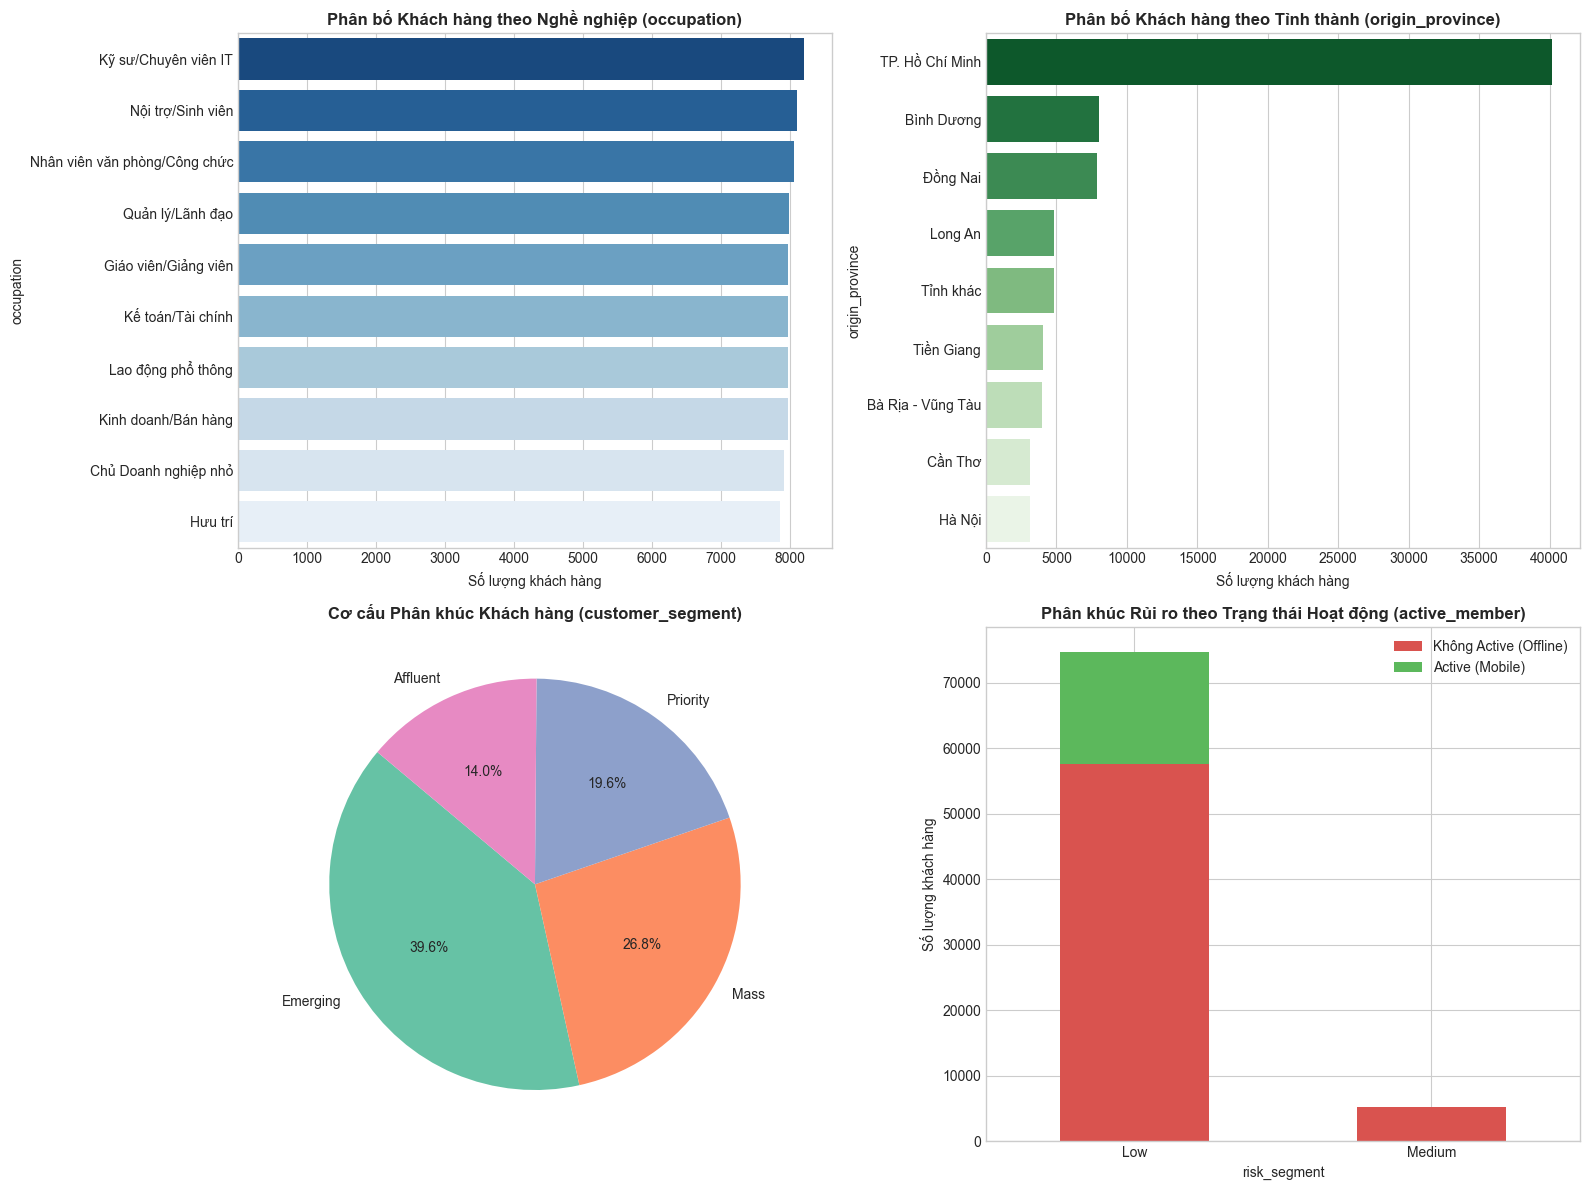

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Nghề nghiệp
occ_counts = df['occupation'].value_counts()
sns.barplot(x=occ_counts.values, y=occ_counts.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title("Phân bố Khách hàng theo Nghề nghiệp (occupation)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Số lượng khách hàng")

# 2. Tỉnh thành
prov_counts = df['origin_province'].value_counts()
sns.barplot(x=prov_counts.values, y=prov_counts.index, ax=axes[0, 1], palette='Greens_r')
axes[0, 1].set_title("Phân bố Khách hàng theo Tỉnh thành (origin_province)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Số lượng khách hàng")

# 3. Phân khúc khách hàng
seg_counts = df['customer_segment'].value_counts()
axes[1, 0].pie(seg_counts.values, labels=seg_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set2'))
axes[1, 0].set_title("Cơ cấu Phân khúc Khách hàng (customer_segment)", fontsize=12, fontweight='bold')

# 4. Phân khúc rủi ro & Trạng thái Active
risk_active = pd.crosstab(df['risk_segment'], df['active_member'])
risk_active.plot(kind='bar', stacked=True, ax=axes[1, 1], color=['#d9534f', '#5cb85c'])
axes[1, 1].set_title("Phân khúc Rủi ro theo Trạng thái Hoạt động (active_member)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Số lượng khách hàng")
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)
axes[1, 1].legend(["Không Active (Offline)", "Active (Mobile)"])

plt.tight_layout()
plt.show()


### 2.7 Thống Kê Mô Tả, Độ Lệch (Skewness) & Khảo Sát Ngoại Lai (Boxplot Outlier Audit)
Phân tích các thuộc tính định lượng qua thước đo trung tâm (Mean, Median), độ phân tán (Std, IQR) và hệ số bất đối xứng (Skewness). Đặc biệt kiểm tra các thuộc tính có độ lệch phải nặng làm cơ sở vững chắc cho bước kỹ nghệ đặc trưng (Log-transform).


,count,mean,std,min,25%,50%,75%,max,skewness
id,80000.0,4.000050e+04,2.309416e+04,1.000000e+00,2.000075e+04,4.000050e+04,6.000025e+04,8.000000e+04,0.000000
credit_sco,80000.0,6.843211e+02,5.116973e+01,4.950000e+02,6.490000e+02,6.820000e+02,7.180000e+02,8.000000e+02,0.113878
age,80000.0,4.938186e+01,1.506748e+01,2.000000e+01,3.800000e+01,4.700000e+01,5.800000e+01,9.000000e+01,0.638930
balance,80000.0,6.118320e+07,8.868620e+07,4.086630e+05,1.462592e+07,3.090276e+07,6.960994e+07,1.000000e+09,4.119595
monthly_ir,80000.0,3.778820e+07,3.655107e+07,3.000000e+06,1.400000e+07,2.300000e+07,4.700000e+07,2.160000e+08,1.732233
tenure_ye,80000.0,1.777250e+00,1.315828e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,0.124212
married,80000.0,9.708250e-01,6.946977e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,0.939486
nums_card,80000.0,2.634688e+00,1.218556e+00,1.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,0.459686
nums_service,80000.0,3.564425e+00,2.002448e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,8.000000e+00,0.584103
last_transaction_month,80000.0,8.831755e+06,3.378683e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e+08,8.216746


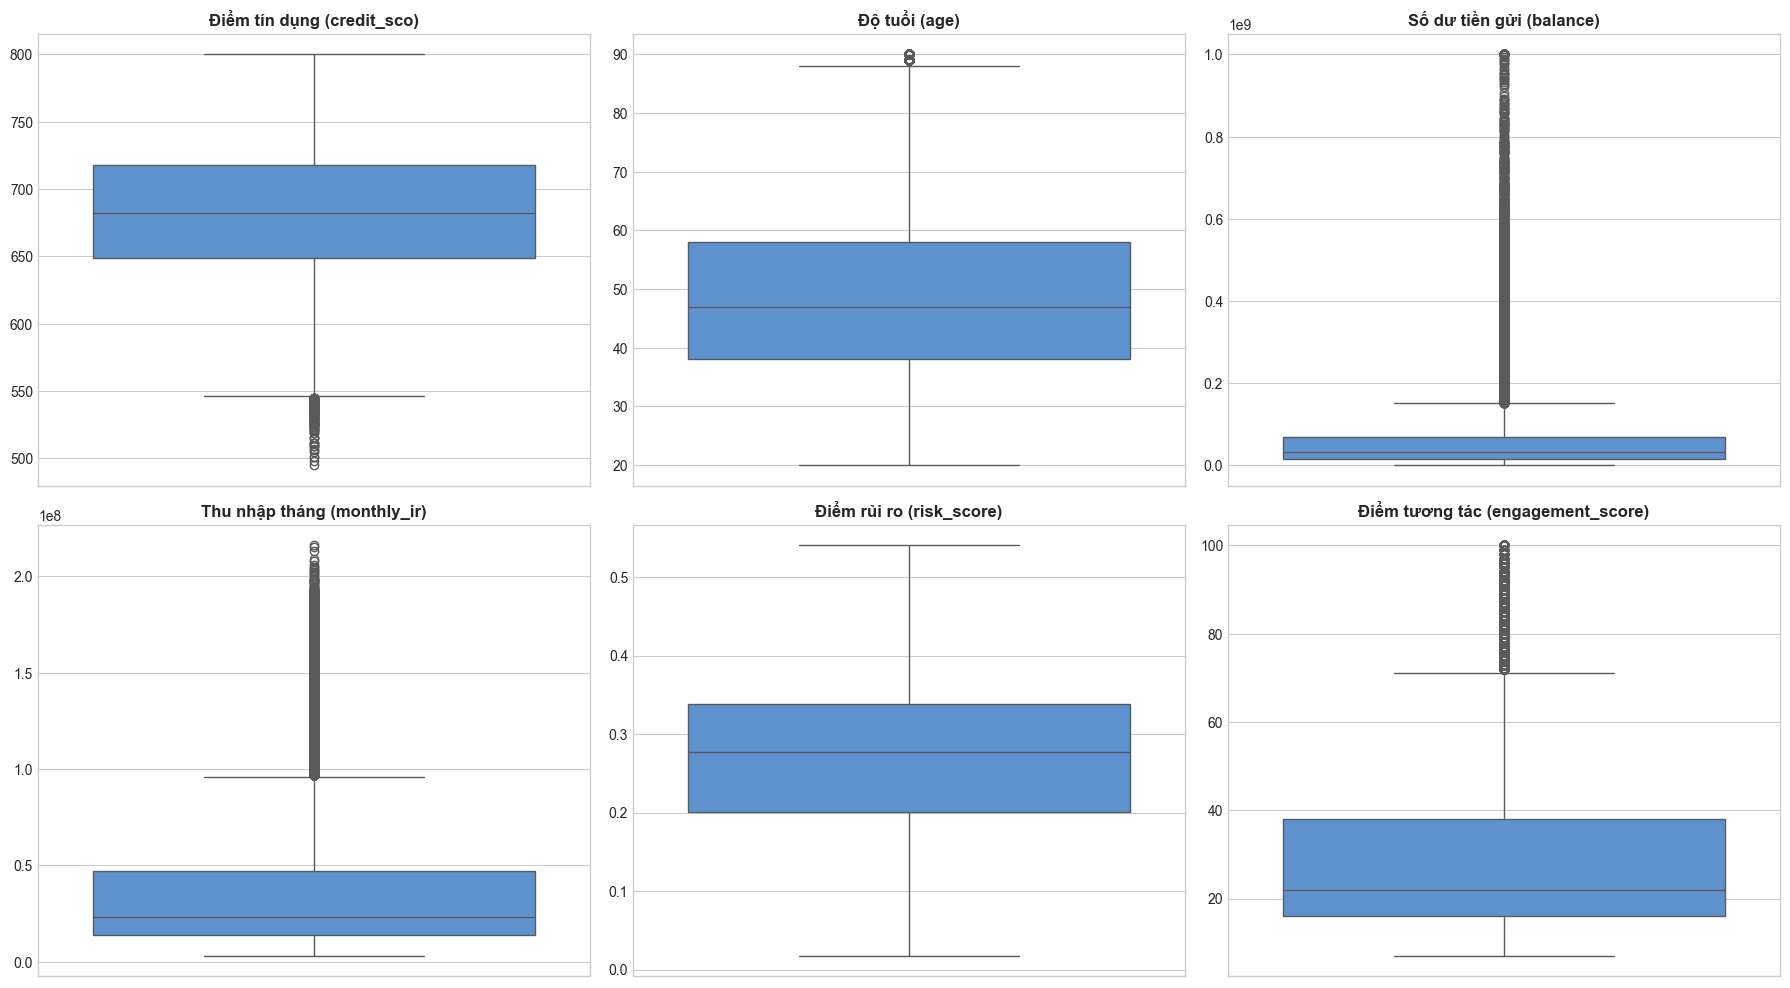

🔍 Đánh giá Skewness & Cần thiết của bước Log-transform:
  - Số dư (balance)     : Skewness = 4.12 (Lệch phải cao, khoảng chênh lệch tài sản lớn).
  - Thu nhập (monthly_ir): Skewness = 1.73 (Lệch phải cao).
  -> Kết luận: Bắt buộc chuẩn hóa phi tuyến bằng Log1p để kéo phân phối về dạng tiệm cận chuẩn trước khi đưa vào mô hình tuyến tính Softmax.


In [9]:
# Thống kê mô tả mở rộng kèm Skewness
desc_df = df.describe().T
numeric_cols = df.select_dtypes(include=[np.number]).columns
skew_vals = df[numeric_cols].skew()
desc_df['skewness'] = skew_vals
display(desc_df[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']])

# Trực quan hóa Boxplot phát hiện ngoại lai (Outlier Detection)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
cols_to_plot = ['credit_sco', 'age', 'balance', 'monthly_ir', 'risk_score', 'engagement_score']
titles = ['Điểm tín dụng (credit_sco)', 'Độ tuổi (age)', 'Số dư tiền gửi (balance)', 
          'Thu nhập tháng (monthly_ir)', 'Điểm rủi ro (risk_score)', 'Điểm tương tác (engagement_score)']

for ax, col, title in zip(axes.flatten(), cols_to_plot, titles):
    sns.boxplot(y=df[col], ax=ax, color='#4A90E2')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("🔍 Đánh giá Skewness & Cần thiết của bước Log-transform:")
print(f"  - Số dư (balance)     : Skewness = {df['balance'].skew():.2f} (Lệch phải cao, khoảng chênh lệch tài sản lớn).")
print(f"  - Thu nhập (monthly_ir): Skewness = {df['monthly_ir'].skew():.2f} (Lệch phải cao).")
print("  -> Kết luận: Bắt buộc chuẩn hóa phi tuyến bằng Log1p để kéo phân phối về dạng tiệm cận chuẩn trước khi đưa vào mô hình tuyến tính Softmax.")


## Section 3: Phân Tích Phân Phối Nhãn (Class Distribution)
Quan sát biến mục tiêu `loyalty_level`. Vấn đề mất cân bằng dữ liệu (imbalanced data) nghiêm trọng: lớp 'Bronze' chiếm đa số (~86.6%), trong khi lớp 'Gold' chỉ chiếm một phần rất nhỏ (~2.2%). Điều này đòi hỏi các kỹ thuật như phân tầng (stratification) khi chia dữ liệu và các chiến lược đánh giá phù hợp (F1-score, Precision-Recall AUC thay vì Accuracy).

Bảng phân phối biến mục tiêu:


,Count,Percentage (%)
loyalty_level,,
Bronze,69252,86.56
Silver,8977,11.22
Gold,1771,2.21


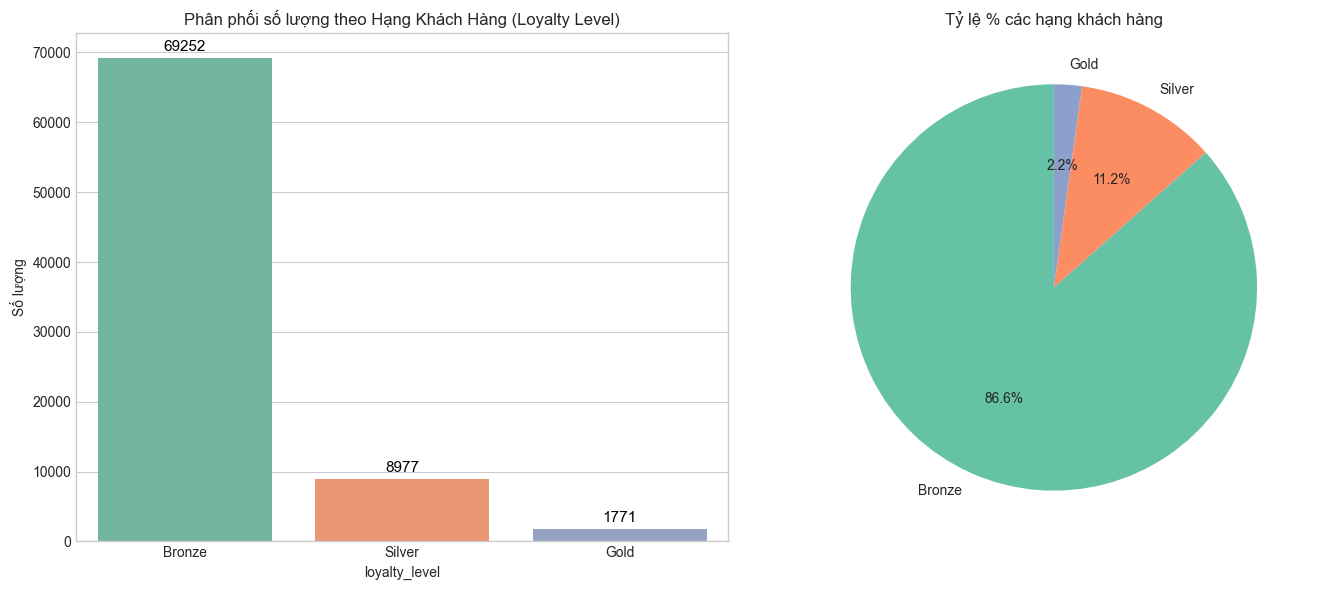

In [10]:
# Tính toán số lượng và tỷ lệ % của mỗi hạng khách hàng
target_col = 'loyalty_level'
class_counts = df[target_col].value_counts()
class_props = df[target_col].value_counts(normalize=True) * 100

distribution_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_props.round(2)
})
print("Bảng phân phối biến mục tiêu:")
display(distribution_df)

# Trực quan hóa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart
sns.countplot(data=df, x=target_col, order=class_counts.index, ax=ax1, palette='Set2')
ax1.set_title('Phân phối số lượng theo Hạng Khách Hàng (Loyalty Level)')
ax1.set_ylabel('Số lượng')

# Thêm nhãn số lượng trên các cột
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                 textcoords='offset points')

# Pie chart
ax2.pie(class_props, labels=class_props.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'), startangle=90)
ax2.set_title('Tỷ lệ % các hạng khách hàng')

plt.tight_layout()
plt.show()


## Section 4: Kiểm Định Rò Rỉ Quy Tắc Chính Sách (Policy Rule Audit)

**Vấn đề Data Leakage (Rò rỉ dữ liệu):** Trong nhiều bài toán phân khúc, các nhãn đôi khi được tạo ra từ một tập hợp các quy tắc tính điểm cứng (hard-coded rules). Ví dụ, hạng Gold có thể được gán tự động nếu `tenure_ye > X` và `engagement_score > Y`. Nếu ta đưa các biến này vào mô hình dự đoán, mô hình sẽ học thuộc (memorize) chính quy tắc này thay vì khám phá quy luật hành vi thực sự. Kết quả là Accuracy đạt ~100%, nhưng mô hình không có giá trị thực tiễn.

**Cách phát hiện:** Chúng ta huấn luyện một cây quyết định nông (Decision Tree, `max_depth=5`) trên tất cả các đặc trưng. Nếu Accuracy ~ 100% và chỉ 1-2 biến có mức độ quan trọng (Feature Importance) cực kỳ cao, chúng ta đã phát hiện được biến rò rỉ (leakage). Các biến đó cần được loại bỏ trước khi huấn luyện mô hình thực.

Độ chính xác của Decision Tree (Audit Model): 1.0000 (100.00%)



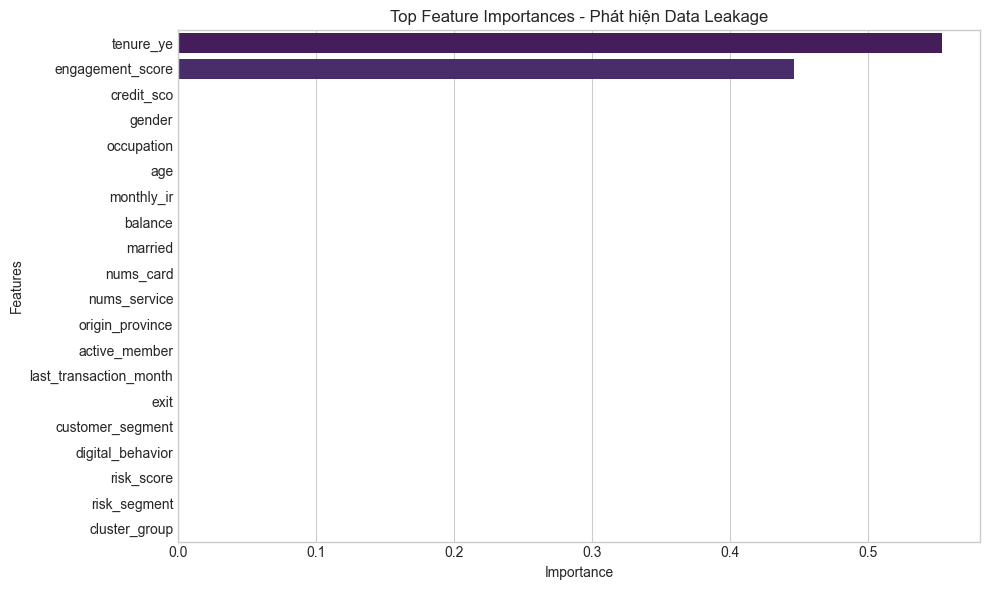

In [11]:
# Chuẩn bị dữ liệu cho Leakage Audit
# Encode categorical variables (Label Encoding tạm thời)
df_audit = df.copy()
drop_cols = ['id', 'full_name', 'address', 'last_active_date', 'created_date'] # Xóa các biến định danh không mang tính dự báo
df_audit.drop(columns=[col for col in drop_cols if col in df_audit.columns], inplace=True)

# Xử lý categorical: sử dụng Label Encoder
categorical_cols = df_audit.select_dtypes(include=['object', 'category']).columns.drop('loyalty_level', errors='ignore')
for col in categorical_cols:
    df_audit[col] = LabelEncoder().fit_transform(df_audit[col].astype(str))

X_audit = df_audit.drop(columns=[target_col])
y_audit = LabelEncoder().fit_transform(df_audit[target_col])

# Train Decision Tree nông
dt_audit = DecisionTreeClassifier(max_depth=5, random_state=SEED)
dt_audit.fit(X_audit, y_audit)

acc = dt_audit.score(X_audit, y_audit)
print(f"Độ chính xác của Decision Tree (Audit Model): {acc:.4f} ({(acc*100):.2f}%)\n")

# Trực quan hóa Feature Importances
importances = dt_audit.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': X_audit.columns, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top Feature Importances - Phát hiện Data Leakage')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [12]:
# In các quy tắc của cây quyết định dưới dạng văn bản
print("Các quy tắc quyết định (Decision Rules):\n")
tree_rules = export_text(dt_audit, feature_names=list(X_audit.columns))
print(tree_rules)

print("\n=> KẾT LUẬN: Nếu 'tenure_ye' và 'engagement_score' chia cắt toàn bộ các lớp (hoặc gần toàn bộ), ")
print("đó là các biến dùng để định nghĩa nhãn (policy rules) và CẦN PHẢI LOẠI BỎ.")


Các quy tắc quyết định (Decision Rules):

|--- engagement_score <= 34.50
|   |--- class: 0
|--- engagement_score >  34.50
|   |--- tenure_ye <= 0.50
|   |   |--- class: 0
|   |--- tenure_ye >  0.50
|   |   |--- tenure_ye <= 2.50
|   |   |   |--- class: 2
|   |   |--- tenure_ye >  2.50
|   |   |   |--- engagement_score <= 54.50
|   |   |   |   |--- class: 2
|   |   |   |--- engagement_score >  54.50
|   |   |   |   |--- class: 1


=> KẾT LUẬN: Nếu 'tenure_ye' và 'engagement_score' chia cắt toàn bộ các lớp (hoặc gần toàn bộ), 
đó là các biến dùng để định nghĩa nhãn (policy rules) và CẦN PHẢI LOẠI BỎ.


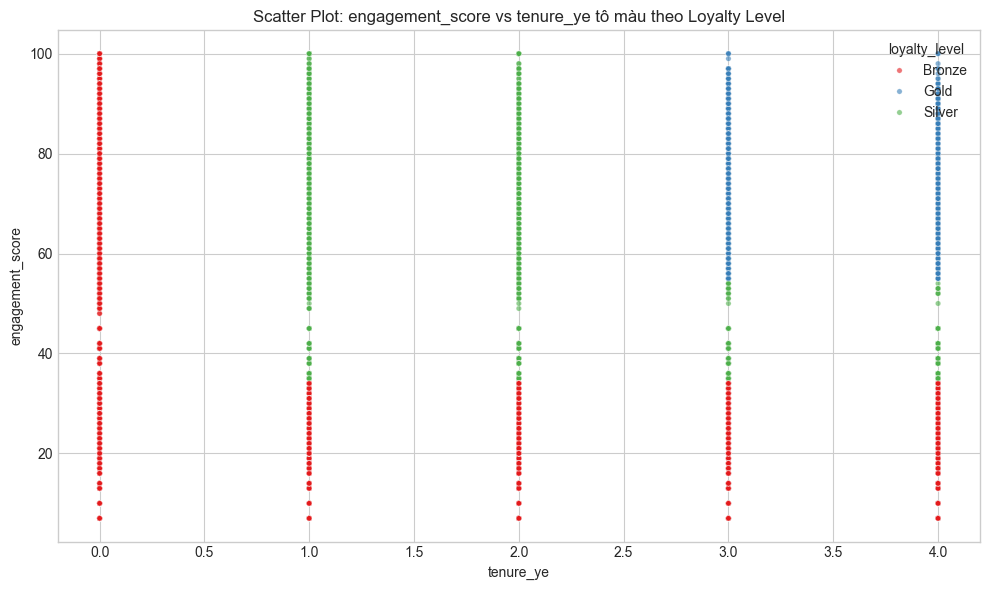

In [13]:
# Trực quan hóa ranh giới bằng Scatter Plot nếu tồn tại 'engagement_score' và 'tenure_ye'
if 'engagement_score' in df.columns and 'tenure_ye' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df, x='tenure_ye', y='engagement_score', hue=target_col, 
                    palette='Set1', alpha=0.6, s=15)
    plt.title('Scatter Plot: engagement_score vs tenure_ye tô màu theo Loyalty Level')
    plt.tight_layout()
    plt.show()


## Section 5: Feature Engineering
Tạo các đặc trưng mới (features) giúp mô hình dự đoán tốt hơn:
- `balance_to_income`: Số dư tài khoản chia cho thu nhập ước tính hàng năm (`monthly_ir` * 12). Giúp mô tả tỷ lệ tiết kiệm so với thu nhập.
- `service_per_card`: Tỷ lệ số sản phẩm sử dụng (`num_of_products`) trên số thẻ tín dụng (`credit_card`). 
- `log_balance` & `log_monthly_ir`: Transform bằng hàm log (log1p) giúp giảm độ lệch (skewness) của các biến có phân phối đuôi dài.

In [14]:
df_processed = df.copy()

# Tính balance_to_income
# Xử lý division by zero (nếu monthly_ir = 0)
df_processed['balance_to_income'] = df_processed['balance'] / (df_processed['monthly_ir'] * 12).replace(0, np.nan)
df_processed['balance_to_income'] = df_processed['balance_to_income'].fillna(0) # Hoặc giá trị mặc định hợp lý khác

# Tính service_per_card
df_processed['service_per_card'] = df_processed['nums_service'] / df_processed['nums_card'].replace(0, np.nan)
df_processed['service_per_card'] = df_processed['service_per_card'].fillna(0)

# Log transform cho balance và monthly_ir (clip(0) để đảm bảo không có giá trị âm trước khi lấy log)
df_processed['log_balance'] = np.log1p(df_processed['balance'].clip(lower=0))
df_processed['log_monthly_ir'] = np.log1p(df_processed['monthly_ir'].clip(lower=0))

# In thống kê các feature mới
new_features = ['balance_to_income', 'service_per_card', 'log_balance', 'log_monthly_ir']
display(df_processed[new_features].describe())


,balance_to_income,service_per_card,log_balance,log_monthly_ir
count,80000.000000,80000.000000,80000.000000,80000.000000
mean,0.133963,1.658675,17.282559,17.061692
std,0.109996,1.283870,1.137684,0.866342
min,0.005676,0.200000,12.920649,14.914123
25%,0.064320,0.800000,16.498306,16.454568
50%,0.103764,1.333333,17.246356,16.951005
75%,0.167808,2.000000,18.058418,17.665658
max,2.795866,8.000000,20.723266,19.190789


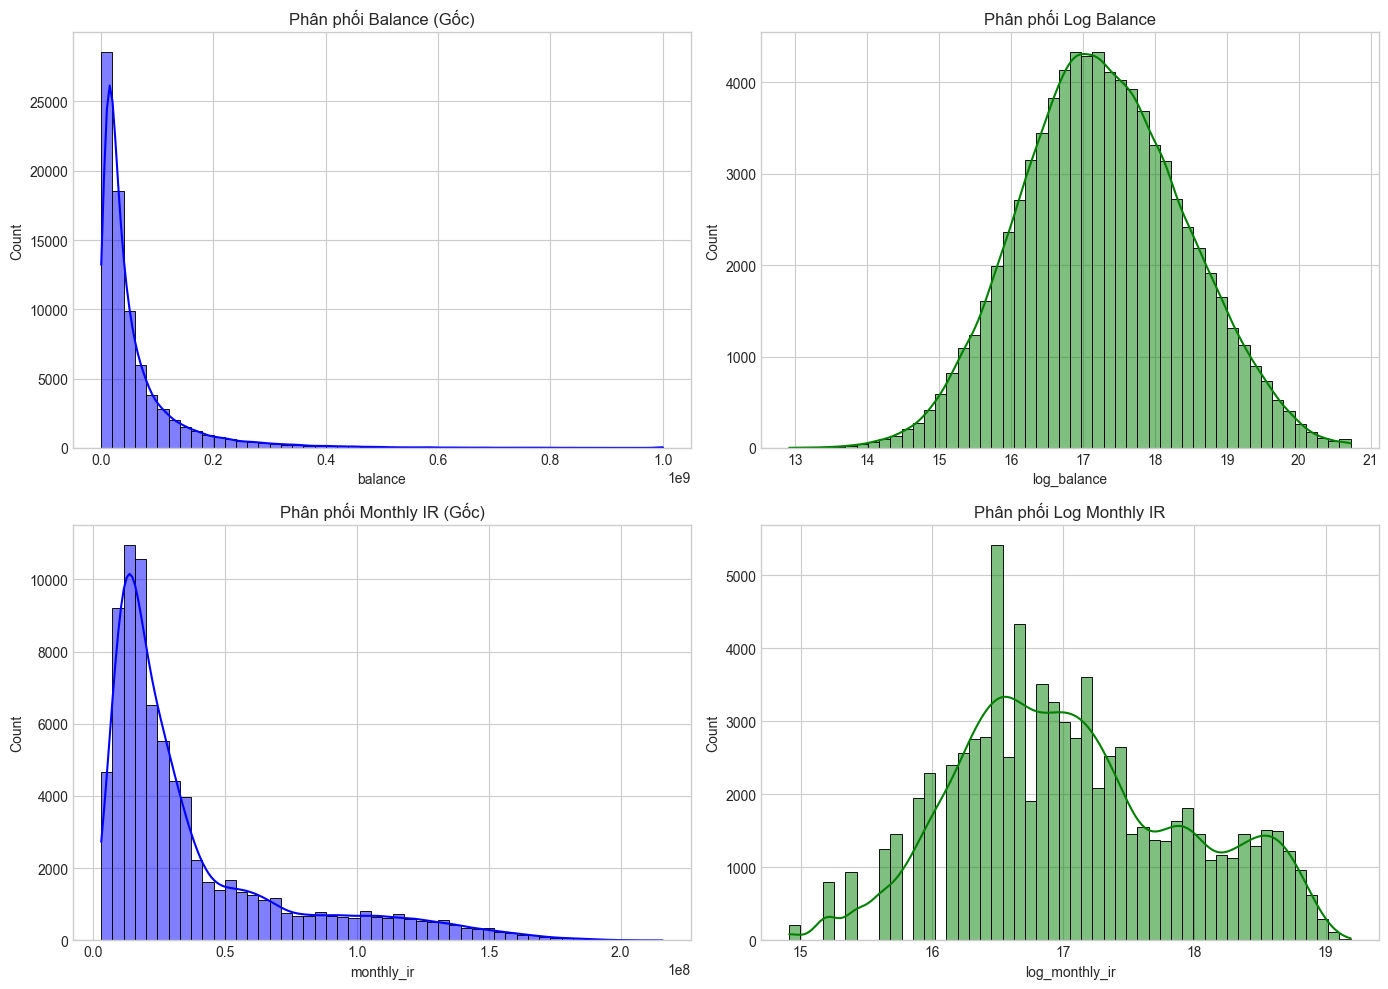

In [15]:
# Vẽ phân phối trước và sau khi log-transform
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_processed['balance'], bins=50, kde=True, ax=axes[0,0], color='blue')
axes[0,0].set_title('Phân phối Balance (Gốc)')

sns.histplot(df_processed['log_balance'], bins=50, kde=True, ax=axes[0,1], color='green')
axes[0,1].set_title('Phân phối Log Balance')

sns.histplot(df_processed['monthly_ir'], bins=50, kde=True, ax=axes[1,0], color='blue')
axes[1,0].set_title('Phân phối Monthly IR (Gốc)')

sns.histplot(df_processed['log_monthly_ir'], bins=50, kde=True, ax=axes[1,1], color='green')
axes[1,1].set_title('Phân phối Log Monthly IR')

plt.tight_layout()
plt.show()


## Section 6: Loại Bỏ Biến Rò Rỉ & Biến Định Danh
Tiến hành drop các biến rò rỉ (như đã phân tích ở Section 4) và biến định danh (như `id`, `full_name`, v.v.).
Encode biến mục tiêu `loyalty_level` thành chuỗi số: `Bronze=0, Silver=1, Gold=2`.

In [16]:
cols_to_drop = ['id', 'full_name', 'address', 'tenure_ye', 'engagement_score', 'last_active_date', 'created_date']
df_final = df_processed.drop(columns=[col for col in cols_to_drop if col in df_processed.columns])

# Encode target
target_mapping = {'Bronze': 0, 'Silver': 1, 'Gold': 2}
if df_final[target_col].dtype == 'object' or df_final[target_col].dtype == 'category':
    df_final[target_col] = df_final[target_col].map(target_mapping)

# Xử lý categorical features còn lại bằng cách tạo biến giả (One-Hot Encoding hoặc Label Encoding tùy ý)
# Ở đây, với các biến danh mục không có thứ tự (như giới tính, quốc gia), pd.get_dummies() là lựa chọn phổ biến.
cat_features = df_final.select_dtypes(include=['object', 'category']).columns
df_final = pd.get_dummies(df_final, columns=cat_features, drop_first=True)

print("Kiểu dữ liệu của các cột sau khi xử lý:")
print(df_final.dtypes)


Kiểu dữ liệu của các cột sau khi xử lý:
credit_sco                                    int64
age                                           int64
balance                                       int64
monthly_ir                                    int64
married                                       int64
nums_card                                     int64
nums_service                                  int64
active_member                                  bool
last_transaction_month                        int64
exit                                           bool
loyalty_level                                 int64
risk_score                                  float64
cluster_group                                 int64
balance_to_income                           float64
service_per_card                            float64
log_balance                                 float64
log_monthly_ir                              float64
gender_male                                    bool
occupation_Giáo viên/Giả

## Section 7: Kiểm Tra Đa Cộng Tuyến (VIF Check)
VIF (Variance Inflation Factor) đo lường mức độ đa cộng tuyến của các đặc trưng. 
Một giá trị `VIF > 5` cho thấy đặc trưng đó có tương quan tuyến tính rất mạnh với các đặc trưng khác, có thể làm giảm khả năng khái quát của một số mô hình tuyến tính.
**Lưu ý:** Việc đo VIF thường nên được thực hiện trên dữ liệu đã chuẩn hóa (Standardized).

In [17]:
# Tách biến độc lập để tính VIF (chỉ dùng numeric, loại bỏ target)
X_vif = df_final.drop(columns=[target_col]).astype(float)

# Chuẩn hóa dữ liệu trước khi tính VIF
scaler_vif = StandardScaler()
X_vif_scaled = scaler_vif.fit_transform(X_vif)
X_vif_scaled_df = pd.DataFrame(X_vif_scaled, columns=X_vif.columns)

# Tính VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_scaled_df.columns
# Lay mau 10,000 dong de tinh VIF nhanh chong ma van chinh xac
X_sample = X_vif_scaled_df.sample(min(5000, len(X_vif_scaled_df)), random_state=SEED).values
vif_data["VIF"] = [variance_inflation_factor(X_sample, i) for i in range(X_vif_scaled_df.shape[1])]

vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

# Hiển thị và highlight các đặc trưng có VIF > 5
def highlight_vif(val):
    color = 'red' if val > 5 else 'black'
    return f'color: {color}'

display(vif_data.style.map(highlight_vif, subset=['VIF']))

# Lưu ý: Các biến log_balance và balance, log_monthly_ir và monthly_ir thường có VIF cao do tính toán từ nhau.
# Trong bước modeling, ta thường chỉ giữ lại một trong hai.


,Feature,VIF
0,active_member,1000799917193443.500000
1,digital_behavior_offline,1000799917193443.500000
2,risk_score,44.503947
3,log_monthly_ir,40.046050
4,monthly_ir,20.046590
5,log_balance,14.834042
6,customer_segment_Mass,10.662677
7,occupation_Nội trợ/Sinh viên,8.335333
8,occupation_Lao động phổ thông,7.948368
9,occupation_Hưu trí,7.262655


## Section 8: Chia Tập Dữ Liệu Stratified (70/15/15)
Dữ liệu mất cân bằng nặng cần dùng chia tách phân tầng (`stratify=y`) để đảm bảo tỷ lệ lớp 'Gold' (và các lớp khác) được giữ nguyên giữa Train, Validation và Test set.
Tỷ lệ phân chia: 70% Train, 15% Validation, 15% Test.

In [18]:
X = df_final.drop(columns=[target_col])
y = df_final[target_col]

# Chia tập Train (70%) và Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)

# Chia tiếp Temp thành Validation (15%) và Test (15%)
# test_size ở đây là 0.5 của 30% -> 15% của toàn bộ
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print("Phân phối nhãn trong từng tập:")
print("Train Set (70%):")
print(y_train.value_counts(normalize=True) * 100)
print("\nValidation Set (15%):")
print(y_val.value_counts(normalize=True) * 100)
print("\nTest Set (15%):")
print(y_test.value_counts(normalize=True) * 100)

# Chuẩn hóa dữ liệu (Standardization)
# Fit scaler chỉ trên Train, sau đó transform Val và Test để tránh data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Lưu dữ liệu vào data/processed/
processed_dir = DATA_DIR / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)

np.save(processed_dir / 'X_train.npy', X_train_scaled)
np.save(processed_dir / 'X_val.npy', X_val_scaled)
np.save(processed_dir / 'X_test.npy', X_test_scaled)
np.save(processed_dir / 'y_train.npy', y_train.values)
np.save(processed_dir / 'y_val.npy', y_val.values)
np.save(processed_dir / 'y_test.npy', y_test.values)

# Lưu cả feature names để dùng sau này
import json
with open(processed_dir / 'feature_names.json', 'w') as f:
    json.dump(list(X.columns), f)

print(f"\nĐã lưu các file numpy arrays vào: {processed_dir}")

pd.DataFrame({'feature': list(X.columns)}).to_csv(processed_dir / 'feature_names.csv', index=False)


Phân phối nhãn trong từng tập:
Train Set (70%):
loyalty_level
0    86.564286
1    11.221429
2     2.214286
Name: proportion, dtype: float64

Validation Set (15%):
loyalty_level
0    86.566667
1    11.216667
2     2.216667
Name: proportion, dtype: float64

Test Set (15%):
loyalty_level
0    86.566667
1    11.225000
2     2.208333
Name: proportion, dtype: float64

Đã lưu các file numpy arrays vào: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 4\01. Topic team\Working file\data\processed


## Section 9: Tổng Kết
Tóm tắt các đặc trưng và quy mô dữ liệu trước khi đưa vào mô hình hóa.

In [19]:
summary = pd.DataFrame({
    'Tập dữ liệu': ['Train', 'Validation', 'Test'],
    'Số lượng (Rows)': [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    'Số đặc trưng (Columns)': [X_train.shape[1], X_val.shape[1], X_test.shape[1]]
})

print("TÓM TẮT DỮ LIỆU ĐÃ TIỀN XỬ LÝ:")
display(summary)

print("\nDanh sách các đặc trưng được giữ lại huấn luyện:")
for i, col in enumerate(X.columns):
    print(f"{i+1}. {col}")


TÓM TẮT DỮ LIỆU ĐÃ TIỀN XỬ LÝ:


,Tập dữ liệu,Số lượng (Rows),Số đặc trưng (Columns)
0,Train,56000,39
1,Validation,12000,39
2,Test,12000,39



Danh sách các đặc trưng được giữ lại huấn luyện:
1. credit_sco
2. age
3. balance
4. monthly_ir
5. married
6. nums_card
7. nums_service
8. active_member
9. last_transaction_month
10. exit
11. risk_score
12. cluster_group
13. balance_to_income
14. service_per_card
15. log_balance
16. log_monthly_ir
17. gender_male
18. occupation_Giáo viên/Giảng viên
19. occupation_Hưu trí
20. occupation_Kinh doanh/Bán hàng
21. occupation_Kế toán/Tài chính
22. occupation_Kỹ sư/Chuyên viên IT
23. occupation_Lao động phổ thông
24. occupation_Nhân viên văn phòng/Công chức
25. occupation_Nội trợ/Sinh viên
26. occupation_Quản lý/Lãnh đạo
27. origin_province_Bình Dương
28. origin_province_Cần Thơ
29. origin_province_Hà Nội
30. origin_province_Long An
31. origin_province_TP. Hồ Chí Minh
32. origin_province_Tiền Giang
33. origin_province_Tỉnh khác
34. origin_province_Đồng Nai
35. customer_segment_Emerging
36. customer_segment_Mass
37. customer_segment_Priority
38. digital_behavior_offline
39. risk_segment_Medium

In [19]:
print('✅ Notebook 01 hoàn tất - Dữ liệu đã sẵn sàng cho mô hình')

✅ Notebook 01 hoàn tất - Dữ liệu đã sẵn sàng cho mô hình


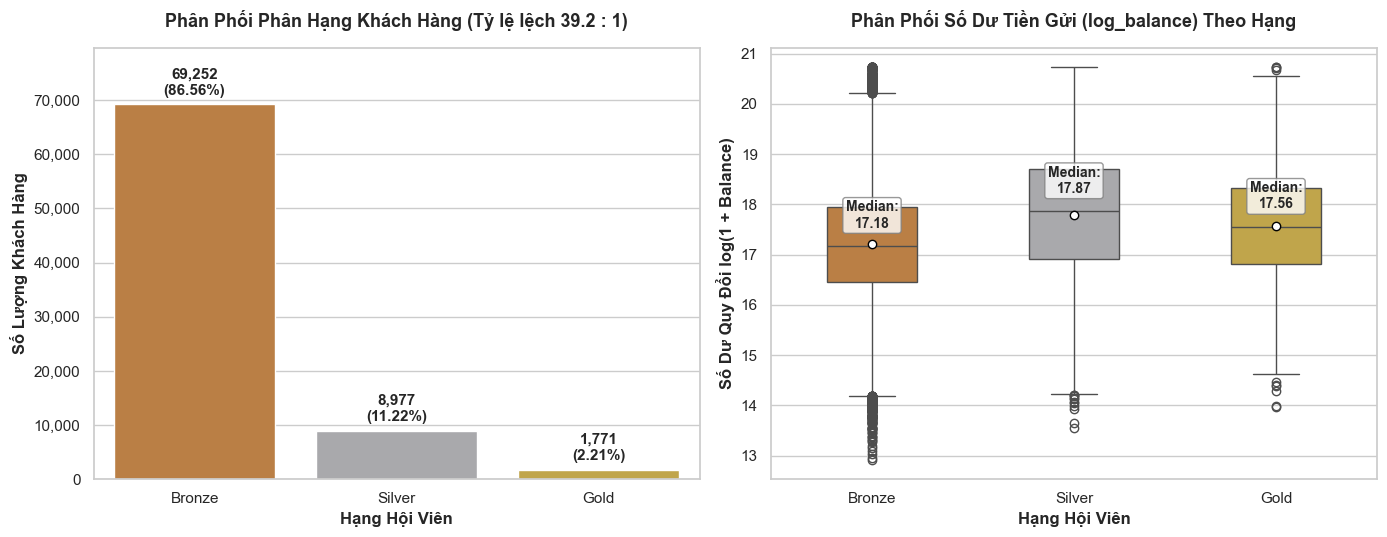

 Đã lưu biểu đồ thành công tại: d:\AIO Tài liệu\05. OFFICIAL COURSE\Module 4\01. Topic team\Working file\notebooks\Figures\eda_imbalance_box.png


In [20]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# -------------------------------------------------------------
# 1. Đọc dữ liệu (nếu biến df đã có sẵn trong Notebook 1 thì bỏ qua bước đọc này)
# -------------------------------------------------------------
if 'df' not in locals():
  # Đường dẫn tới tệp dữ liệu thô hoặc dữ liệu đã tiền xử lý
  data_path = 'data/raw/Bank churn data set 80k.xlsx'
  if os.path.exists(data_path):
    df = pd.read_excel(data_path)
  else:
    # Nếu file nằm cùng thư mục hoặc đường dẫn khác, bạn chỉnh lại tại đây
    df = pd.read_csv('data/raw/Bank churn data set 80k.csv')

# Đảm bảo có cột log_balance
if 'log_balance' not in df.columns and 'balance' in df.columns:
  df['log_balance'] = np.log1p(df['balance'])

# -------------------------------------------------------------
# 2. Thiết lập cấu hình đồ họa chuẩn báo cáo (Style & Palette)
# -------------------------------------------------------------
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.size'] = 11

palette = {
    'Bronze': '#CD7F32',  # Màu đồng
    'Silver': '#A8A9AD',  # Màu bạc
    'Gold': '#D4AF37',  # Màu vàng kim
}
order = ['Bronze', 'Silver', 'Gold']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# -------------------------------------------------------------
# 3. Biểu đồ con 1 (Trái): Phân phối mức độ mất cân bằng lớp
# -------------------------------------------------------------
ax1 = axes[0]
counts = df['loyalty_level'].value_counts()[order]
total = len(df)
percentages = (counts / total) * 100

bars = sns.barplot(
    x=counts.index, y=counts.values, palette=palette, order=order, ax=ax1
)

# Hiển thị số lượng và % trên đầu mỗi cột
for i, (count, pct) in enumerate(zip(counts, percentages)):
  ax1.text(
      i,
      count + (total * 0.015),
      f'{count:,}\n({pct:.2f}%)',
      ha='center',
      va='bottom',
      fontsize=11,
      fontweight='bold',
  )

ax1.set_title(
    'Phân Phối Phân Hạng Khách Hàng (Tỷ lệ lệch 39.2 : 1)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax1.set_xlabel('Hạng Hội Viên', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số Lượng Khách Hàng', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(counts) * 1.15)
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: f'{int(x):,}')
)  # Định dạng dấu phẩy

# -------------------------------------------------------------
# 4. Biểu đồ con 2 (Phải): Biểu đồ hộp phân vị log_balance
# -------------------------------------------------------------
ax2 = axes[1]
sns.boxplot(
    data=df,
    x='loyalty_level',
    y='log_balance',
    order=order,
    palette=palette,
    width=0.45,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black',
        'markersize': '6',
    },
    ax=ax2,
)

# Ghi chú giá trị trung vị (Median) trực tiếp trên các hộp
medians = df.groupby('loyalty_level')['log_balance'].median()[order]
for i, median_val in enumerate(medians):
  ax2.text(
      i,
      median_val + 0.3,
      f'Median:\n{median_val:.2f}',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
      bbox=dict(
          boxstyle='round,pad=0.2',
          facecolor='white',
          edgecolor='gray',
          alpha=0.8,
      ),
  )

ax2.set_title(
    'Phân Phối Số Dư Tiền Gửi (log_balance) Theo Hạng',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax2.set_xlabel('Hạng Hội Viên', fontsize=12, fontweight='bold')
ax2.set_ylabel('Số Dư Quy Đổi log(1 + Balance)', fontsize=12, fontweight='bold')

# -------------------------------------------------------------
# 5. Lưu ảnh độ phân giải cao vào thư mục Figures
# -------------------------------------------------------------
figures_dir = BASE_DIR / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
save_path = figures_dir / 'eda_imbalance_box.png'
plt.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f' Đã lưu biểu đồ thành công tại: {os.path.abspath(save_path)}')